In [2]:
import stim
import stim
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from wrappers.stim_wrapper import (create_circuit_polar_stim_normal, convert_i_to_meas_type, 
simulate_batch_and_save_result_polar_normal)

from wrappers.polar_wrapper import is_q1prep_accepted, get_logical_error_on_accepted_states, get_q1prep_accepted_states

import torch
import torch.nn.functional as F


In [3]:

def create_stim_circuit_polar(n, i, lstate, sim_type, p_error, shots, seed):
    N = 2**(n)
    ancilla_qubits = 2**(n - 1)
    total_qubits = N + ancilla_qubits
    meas_type = convert_i_to_meas_type(i, n, lstate)
    print(meas_type, sim_type, "total qubits:", total_qubits, ", total ancilla:", ancilla_qubits)
    x_ind = 0
    for idx, m_type in enumerate(meas_type):
        if m_type == "x":
            x_ind = idx
            break

    circuit = create_circuit_polar_stim_normal(n, lstate, sim_type, p_error, seed, shots, None, None, None, meas_type, total_qubits, x_ind)
    return circuit

def set_global_seeds(seed=12345):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        

['x', 'z', 'x'] normal total qubits: 12 , total ancilla: 4


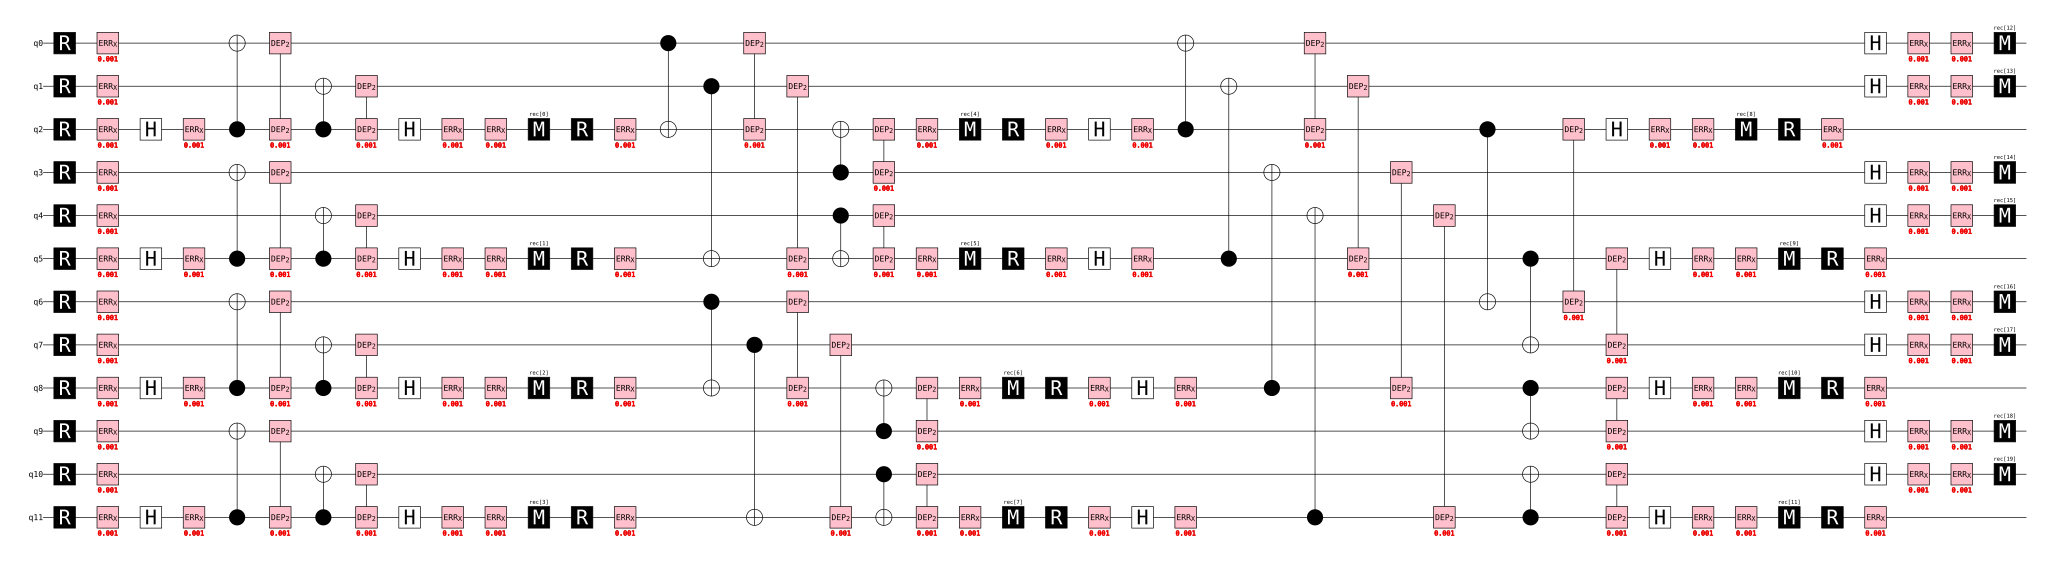

In [4]:
n = 3
i = 4
lstate = "x" 
sim_type = "normal"
p_error = 0.001
shots = 1000
seed = 1234

circuit = create_stim_circuit_polar(n, i, lstate, sim_type, p_error, shots, seed)
circuit.diagram("timeline-svg")

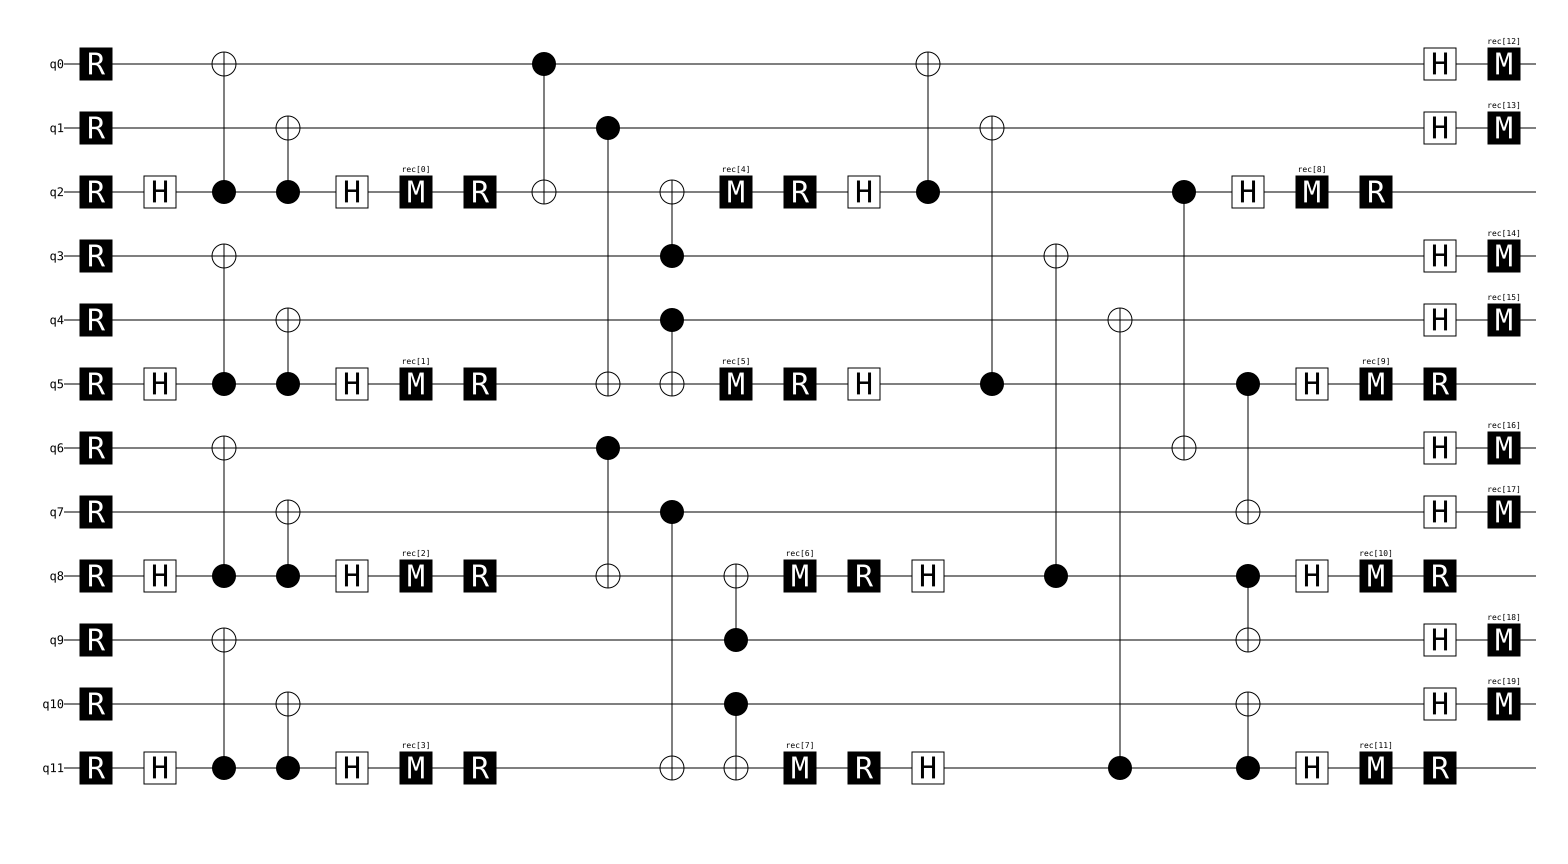

In [5]:
noiseless_circuit = circuit.without_noise()
noiseless_circuit.diagram("timeline-svg")

In [6]:
noiseless_circuit

stim.Circuit('''
    R 0 1 2 3 4 5 6 7 8 9 10 11
    H 2 5 8 11
    CX 2 0 5 3 8 6 11 9 2 1 5 4 8 7 11 10
    H 2 5 8 11
    M 2 5 8 11
    R 2 5 8 11
    CX 0 2 1 5 6 8 7 11 3 2 4 5 9 8 10 11
    M 2 5 8 11
    R 2 5 8 11
    H 2 5 8 11
    CX 2 0 5 1 8 3 11 4 2 6 5 7 8 9 11 10
    H 2 5 8 11
    M 2 5 8 11
    R 2 5 8 11
    H 0 1 3 4 6 7 9 10
    M 0 1 3 4 6 7 9 10
''')

In [9]:
import torch
from torch_geometric.data import Data

# Data qubit mapping: 0:q0, 1:q1, 2:q3, 3:q4, 4:q6, 5:q7, 6:q9, 7:q10
num_data_qubits = 8

# Check connections (data_idx, check_idx)
# Check indices 0..7 are X-checks, 8..11 are Z-checks
x_check_edges = [
    # Round 1
    (0, 0), (1, 0), (2, 1), (3, 1), (4, 2), (5, 2), (6, 3), (7, 3),
    # Round 3
    (0, 4), (4, 4), (1, 5), (5, 5), (2, 6), (6, 6), (3, 7), (7, 7)
]

z_check_edges = [
    # Round 2
    (0, 8), (2, 8), (1, 9), (3, 9), (4, 10), (6, 10), (5, 11), (7, 11)
]

# Build edge_index (bipartite: data_nodes 0..7, check_nodes 8..19)
edges = []
edge_types = []  # 0 for X-edge, 1 for Z-edge

for d, c in x_check_edges:
    c_node = num_data_qubits + c
    edges.extend([[d, c_node], [c_node, d]])  # Undirected edge
    edge_types.extend([0, 0])

for d, c in z_check_edges:
    c_node = num_data_qubits + c
    edges.extend([[d, c_node], [c_node, d]])  # Undirected edge
    edge_types.extend([1, 1])

edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
edge_attr = torch.tensor(edge_types, dtype=torch.long)

# Node features:
# Data nodes (0..7): type=[1, 0, 0]
# X-check nodes (8..15): type=[0, 1, 0]
# Z-check nodes (16..19): type=[0, 0, 1]
node_features = torch.zeros((20, 3), dtype=torch.float)
node_features[:8, 0] = 1.0     # Data qubits
node_features[8:16, 1] = 1.0   # X-checks
node_features[16:, 2] = 1.0    # Z-checks

tanner_graph = Data(x=node_features, edge_index=edge_index, edge_attr=edge_attr)
print(tanner_graph)

Data(x=[20, 3], edge_index=[2, 48], edge_attr=[48])


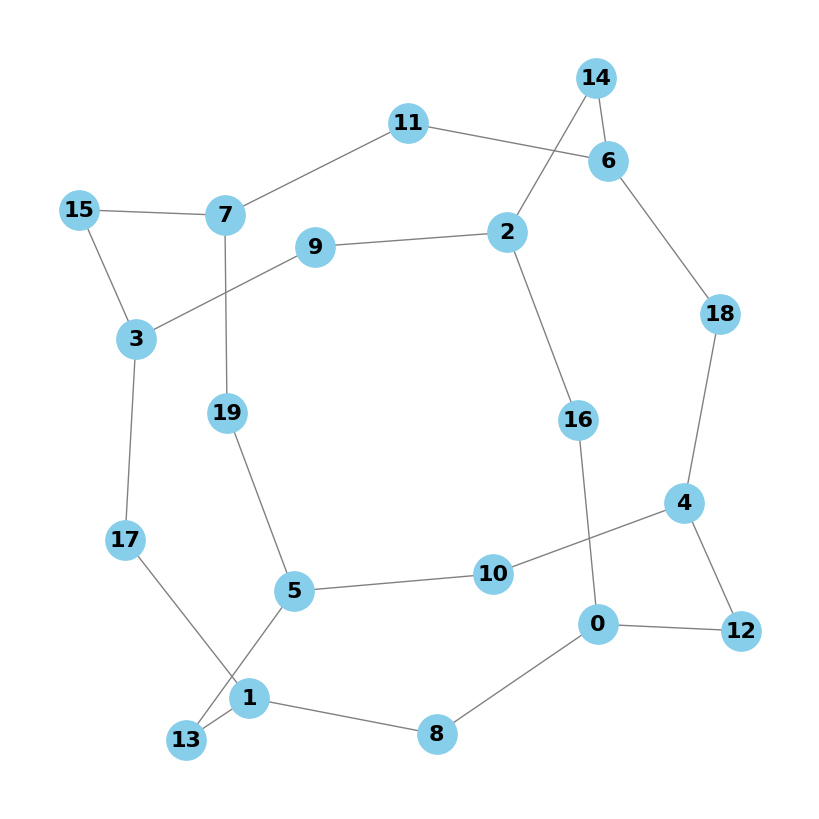

Graph saved as graph_image.png


In [10]:
import torch
from torch_geometric.data import Data
from torch_geometric.utils import to_networkx
import networkx as nx
import matplotlib.pyplot as plt

G = to_networkx(tanner_graph, to_undirected=True)

# 3. Draw the graph using NetworkX and Matplotlib
plt.figure(figsize=(8, 8))  # Set the size of the image
pos = nx.spring_layout(G)  # Choose a layout algorithm for node positioning

# Draw nodes, edges, and labels
nx.draw(G, pos,
        with_labels=True,      # Show node IDs
        node_color='skyblue',  # Color of the nodes
        node_size=800,         # Size of the nodes
        edge_color='gray',     # Color of the edges
        font_size=16,          # Font size for labels
        font_weight='bold')

# 4. Save the plot as an image file
plt.savefig('graph_image.png', format='png', dpi=300) # dpi sets quality

# Optional: Display the plot on screen if running interactively
plt.show()

print("Graph saved as graph_image.png")

In [ ]:
from wrappers.stim_wrapper import (
    simulate_stim_polar_code_normal)

n = 4
lstate = "x" # z is the logical 0, and x is the logical +
sim_type = "normal" # you can choose between "normal" / "m1" which is my proposal
i = 6 
p_error = 0.01
shots = 1e4
seed = 12345

zpos_list = [-1, -1, 1, 3, 6, 7, 22, 15, 90, 31, 362]
zpos_list[n] = i-1

results = simulate_stim_polar_code_normal(n, lstate, sim_type, i, p_error, shots, seed)

# flipped_results = {bit_str[::-1]: count for bit_str, count in results.items()}
sum(results.values())

zpos_list = [-1, -1, 1, 3, 6, 7, 22, 15, 90, 31, 362]
zpos_list[n] = i-1


# this is for the error detection and the verification whether the error can be corrected or not.
count_accept_n, count_logerror, count_undecided, success_n, detect_normal, decoding_normal = get_logical_error_on_accepted_states(n, lstate.upper(), results, zpos_list)
print(count_accept_n, count_accept_n / shots, 1 - success_n, count_logerror, count_undecided)

# 1 - success_n is the logical error rate
# count_accept_n: number of accepted states

# this function is the filter the accepted states and the accepted data qubits
accepted_states, data_qubit_states = get_q1prep_accepted_states(n, lstate, results, zpos_list)
sum(data_qubit_states.values())

2371 0.2371 0.010965837199493844 26 52


2371

{'01111010110011110101': 1,
 '01011100100000000111': 1,
 '01111011111000000001': 1,
 '10100111011011000110': 1,
 '11001010000011000000': 1,
 '11110010011100000001': 1,
 '11011100111011110111': 1,
 '10111001101011000101': 1,
 '00111111010011110111': 1,
 '11100100100011111000': 1,
 '00110011000100110010': 1,
 '00010100100111000000': 1,
 '10110011010111111010': 1,
 '01100101010111110101': 1,
 '10111001010011111011': 1,
 '10001111100000001000': 1,
 '00011011011100110010': 1,
 '11111111001111110110': 1,
 '00001111111100001001': 1,
 '01101001011011001100': 1,
 '01110000101000110011': 1,
 '01001101001100111100': 1,
 '10110111101011110000': 1,
 '01011101011011001001': 1,
 '11000111110111001110': 1,
 '01101101010011001101': 1,
 '01111011101011111111': 1,
 '00011100010100111010': 1,
 '01111000110111001000': 1,
 '11000000100000110010': 1,
 '11000111001111110110': 1,
 '01010001100111001100': 1,
 '00101110110000110011': 1,
 '00111101010000110010': 1,
 '11111010010111001100': 1,
 '101000101111000010

In [11]:
import torch
from torch_geometric.data import HeteroData
import networkx as nx
import matplotlib.pyplot as plt

# 1. Define Parity-Check Matrices
HX = torch.tensor([
    [1, 1, 0, 0, 0, 0, 0, 0],  # X_1
    [0, 0, 1, 1, 0, 0, 0, 0],  # X_2
    [0, 0, 0, 0, 1, 1, 0, 0],  # X_3
    [0, 0, 0, 0, 0, 0, 1, 1],  # X_4
    [1, 0, 0, 0, 1, 0, 0, 0],  # X_5
    [0, 1, 0, 0, 0, 1, 0, 0],  # X_6
    [0, 0, 1, 0, 0, 0, 1, 0],  # X_7
    [0, 0, 0, 1, 0, 0, 0, 1]   # X_8
])

HZ = torch.tensor([
    [1, 0, 1, 0, 0, 0, 0, 0],  # Z_1
    [0, 1, 0, 1, 0, 0, 0, 0],  # Z_2
    [0, 0, 0, 0, 1, 0, 1, 0],  # Z_3
    [0, 0, 0, 0, 0, 1, 0, 1]   # Z_4
])

# 2. Extract Non-Zero Connections (Check Index, Data Index)
x_check_idx, data_idx_x = torch.where(HX == 1)
z_check_idx, data_idx_z = torch.where(HZ == 1)

# 3. Build HeteroData Graph
hetero_graph = HeteroData()

# Node Features: Shape [num_nodes, num_features]
# Dynamic syndromes are injected per sample during training/inference
hetero_graph['data'].x = torch.zeros((8, 1))     # Data qubits (e.g., initial error priors)
hetero_graph['x_check'].x = torch.zeros((8, 1))  # 8 X-check syndrome bits
hetero_graph['z_check'].x = torch.zeros((4, 1))  # 4 Z-check syndrome bits

# Add Undirected Edge Relations
hetero_graph['data', 'connected_to', 'x_check'].edge_index = torch.stack([data_idx_x, x_check_idx])
hetero_graph['x_check', 'connected_to', 'data'].edge_index = torch.stack([x_check_idx, data_idx_x])

hetero_graph['data', 'connected_to', 'z_check'].edge_index = torch.stack([data_idx_z, z_check_idx])
hetero_graph['z_check', 'connected_to', 'data'].edge_index = torch.stack([z_check_idx, data_idx_z])

print(hetero_graph)

HeteroData(
  data={ x=[8, 1] },
  x_check={ x=[8, 1] },
  z_check={ x=[4, 1] },
  (data, connected_to, x_check)={ edge_index=[2, 16] },
  (x_check, connected_to, data)={ edge_index=[2, 16] },
  (data, connected_to, z_check)={ edge_index=[2, 8] },
  (z_check, connected_to, data)={ edge_index=[2, 8] }
)


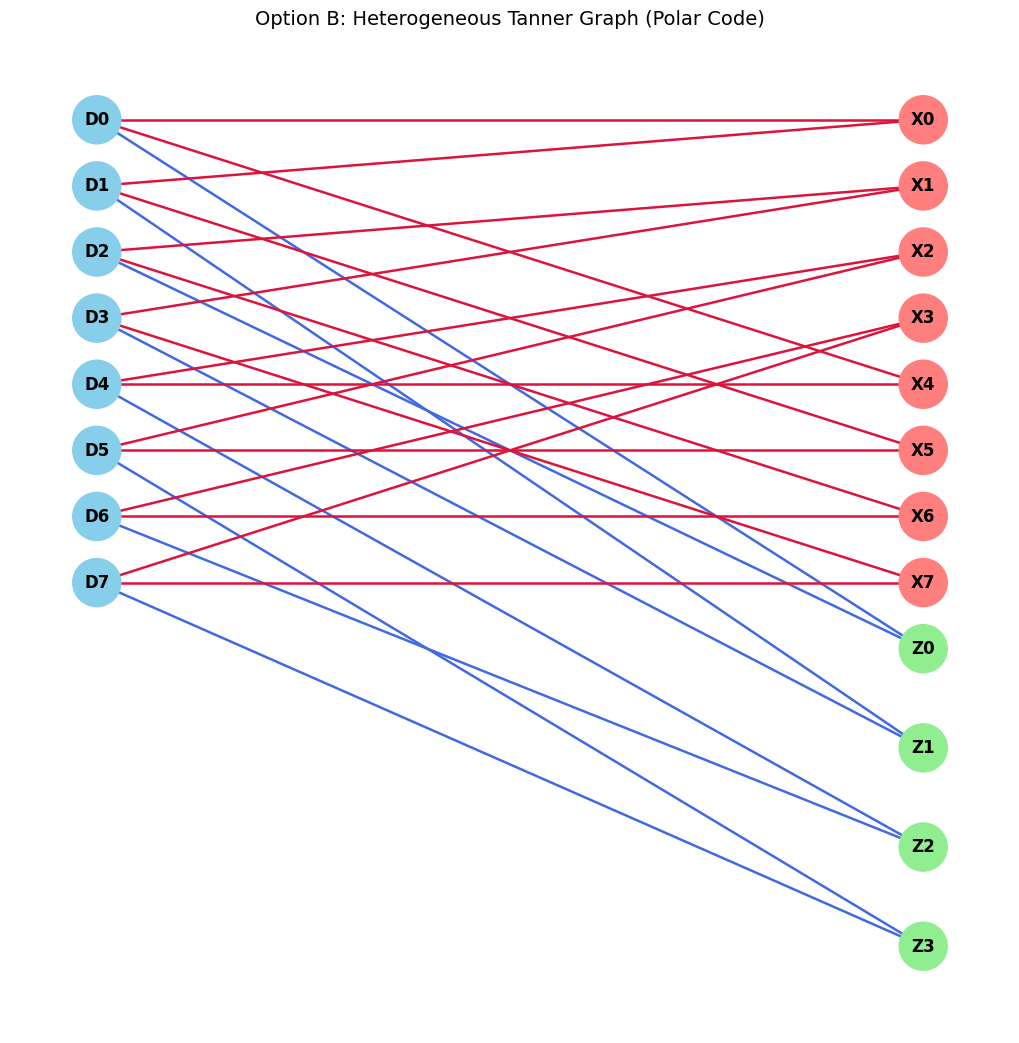

In [12]:
# Convert HeteroData to NetworkX for plotting
G = nx.Graph()

# Add nodes with types
for i in range(8):
    G.add_node(f"D{i}", bipartite=0, type='Data')
for i in range(8):
    G.add_node(f"X{i}", bipartite=1, type='X-Check')
for i in range(4):
    G.add_node(f"Z{i}", bipartite=1, type='Z-Check')

# Add edges
for d, c in zip(data_idx_x.tolist(), x_check_idx.tolist()):
    G.add_edge(f"D{d}", f"X{c}", color='crimson')

for d, c in zip(data_idx_z.tolist(), z_check_idx.tolist()):
    G.add_edge(f"D{d}", f"Z{c}", color='royalblue')

# Layout configuration
pos = {}
# Data qubits on left
for i in range(8):
    pos[f"D{i}"] = (0, 7 - i)
# X-checks top right
for i in range(8):
    pos[f"X{i}"] = (2, 7 - i)
# Z-checks bottom right
for i in range(4):
    pos[f"Z{i}"] = (2, -1 - i * 1.5)

# Color maps
node_colors = ['#87CEEB' if G.nodes[n]['type'] == 'Data' else 
               '#FF7F7F' if G.nodes[n]['type'] == 'X-Check' else '#90EE90' for n in G.nodes]
edge_colors = [G[u][v]['color'] for u, v in G.edges()]

# Plot
plt.figure(figsize=(10, 10))
nx.draw(G, pos, with_labels=True, node_color=node_colors, edge_color=edge_colors, 
        node_size=1200, font_weight='bold', width=1.8)
plt.title("Option B: Heterogeneous Tanner Graph (Polar Code)", fontsize=14)
plt.savefig("hetero_tanner_graph.png", dpi=300, bbox_inches='tight')
plt.show()

In [13]:
from torch_geometric.data import Data

def build_decoupled_graphs(HX, HZ):
    x_check_idx, data_idx_x = torch.where(HX == 1)
    z_check_idx, data_idx_z = torch.where(HZ == 1)

    # --- Graph 1: X-Error Decoder (Uses H_Z matrix, 8 Data + 4 Z-Checks = 12 nodes) ---
    z_node_offset = 8
    edges_gz = torch.cat([
        torch.stack([data_idx_z, z_check_idx + z_node_offset]),
        torch.stack([z_check_idx + z_node_offset, data_idx_z])
    ], dim=1)
    
    graph_X_decoder = Data(edge_index=edges_gz, num_nodes=12)

    # --- Graph 2: Z-Error Decoder (Uses H_X matrix, 8 Data + 8 X-Checks = 16 nodes) ---
    x_node_offset = 8
    edges_gx = torch.cat([
        torch.stack([data_idx_x, x_check_idx + x_node_offset]),
        torch.stack([x_check_idx + x_node_offset, data_idx_x])
    ], dim=1)
    
    graph_Z_decoder = Data(edge_index=edges_gx, num_nodes=16)

    return graph_X_decoder, graph_Z_decoder

graph_X_dec, graph_Z_dec = build_decoupled_graphs(HX, HZ)
print("X-decoder graph:", graph_X_dec)
print("Z-decoder graph:", graph_Z_dec)

X-decoder graph: Data(edge_index=[2, 16], num_nodes=12)
Z-decoder graph: Data(edge_index=[2, 32], num_nodes=16)


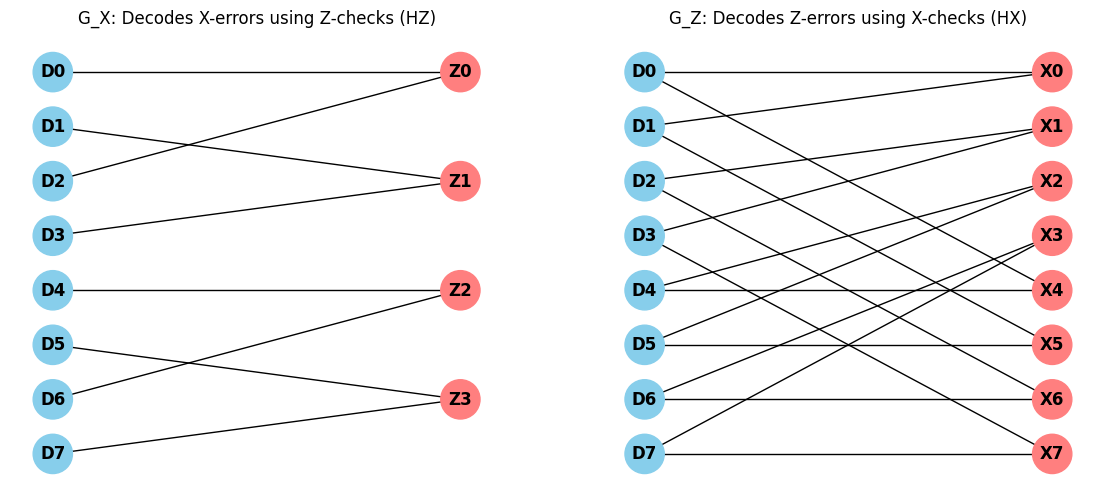

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Helper to plot bipartite PyG Data
def plot_bipartite(ax, num_data, num_checks, edge_index, title, check_prefix="C"):
    G = nx.Graph()
    for d, c in edge_index.t().tolist():
        if d < num_data:
            G.add_edge(f"D{d}", f"{check_prefix}{c - num_data}")
    
    pos = {}
    for i in range(num_data):
        pos[f"D{i}"] = (0, num_data - i)
    for i in range(num_checks):
        pos[f"{check_prefix}{i}"] = (1.5, num_data - (i * num_data / num_checks))

    node_colors = ['#87CEEB' if 'D' in n else '#FF7F7F' for n in G.nodes()]
    nx.draw(G, pos, ax=ax, with_labels=True, node_color=node_colors, node_size=800, font_weight='bold')
    ax.set_title(title, fontsize=12)

plot_bipartite(ax1, 8, 4, graph_X_dec.edge_index, "G_X: Decodes X-errors using Z-checks (HZ)", "Z")
plot_bipartite(ax2, 8, 8, graph_Z_dec.edge_index, "G_Z: Decodes Z-errors using X-checks (HX)", "X")

plt.savefig("decoupled_tanner_graphs.png", dpi=300, bbox_inches='tight')
plt.show()

In [17]:
import torch
from torch_geometric.data import HeteroData

def create_spatiotemporal_tanner_graph(HX_r1, HZ_r2, HX_r3):
    """
    Unrolls 3 measurement rounds into a single static spatiotemporal HeteroData graph.
    """
    data = HeteroData()
    num_data = 8

    # 1. Node counts: Data qubits (8), Round 1 X-checks (4), Round 2 Z-checks (4), Round 3 X-checks (4)
    data['data'].x = torch.zeros((num_data, 2))      # Features: [prior_error, residual]
    data['x_check_r1'].x = torch.zeros((4, 1))       # Syndrome M0..M3
    data['z_check_r2'].x = torch.zeros((4, 1))       # Syndrome M4..M7
    data['x_check_r3'].x = torch.zeros((4, 1))       # Syndrome M8..M11

    # 2. Extract spatial connections per round
    r1_x_idx, r1_d_idx = torch.where(HX_r1 == 1)
    r2_z_idx, r2_d_idx = torch.where(HZ_r2 == 1)
    r3_x_idx, r3_d_idx = torch.where(HX_r3 == 1)

    # 3. Add spatial edges
    data['data', 'measured_by', 'x_check_r1'].edge_index = torch.stack([r1_d_idx, r1_x_idx])
    data['x_check_r1', 'measures', 'data'].edge_index = torch.stack([r1_x_idx, r1_d_idx])

    data['data', 'measured_by', 'z_check_r2'].edge_index = torch.stack([r2_d_idx, r2_z_idx])
    data['z_check_r2', 'measures', 'data'].edge_index = torch.stack([r2_z_idx, r2_d_idx])

    data['data', 'measured_by', 'x_check_r3'].edge_index = torch.stack([r3_d_idx, r3_x_idx])
    data['x_check_r3', 'measures', 'data'].edge_index = torch.stack([r3_x_idx, r3_d_idx])

    # 4. Add temporal edges between consecutive check rounds (tracking syndrome persistence)
    # Connects checks operating on overlapping qubits across time
    temp_r1_r3_x1, temp_r1_r3_x2 = torch.where(HX_r1 @ HX_r3.T > 0)
    data['x_check_r1', 'evolves_to', 'x_check_r3'].edge_index = torch.stack([temp_r1_r3_x1, temp_r1_r3_x2])

    return data

In [18]:
import numpy as np

def compute_polar_llrs_n8(p_error=0.05, syndrome_bits=None):
    """
    Simulates forward LLR propagation across the 4 stages of an N=8 (n=3) Polar Graph.
    
    Parameters:
      p_error: Physical depolarizing noise rate (e.g., 0.05)
      syndrome_bits: Hard syndrome observations [s0..s7] from Steane/internal checks
    """
    if syndrome_bits is None:
        syndrome_bits = np.zeros(8, dtype=int)

    # Matrix to store LLRs across all 4 stages: Shape [4 stages, 8 nodes]
    LLR_matrix = np.zeros((4, 8))

    # --- STAGE 0: Initial Channel LLRs ---
    init_llr = np.log((1.0 - p_error) / p_error)
    LLR_matrix[0, :] = init_llr

    # Define exact boxplus f- operator
    def f_minus(a, b):
        ta = np.tanh(a / 2.0)
        tb = np.tanh(b / 2.0)
        val = np.clip(ta * tb, -0.99999999, 0.99999999)
        return 2.0 * np.arctanh(val)

    # Define variable f+ operator incorporating syndrome bit s
    def f_plus(a, b, s=0):
        return b + ((-1)**s) * a

    # --- STAGE 1: Pairs separated by N/2 = 4 ---
    # Connected pairs: (0,4), (1,5), (2,6), (3,7)
    for i in range(4):
        a = LLR_matrix[0, i]
        b = LLR_matrix[0, i + 4]
        LLR_matrix[1, i]     = f_minus(a, b)
        LLR_matrix[1, i + 4] = f_plus(a, b, s=syndrome_bits[i])

    # --- STAGE 2: Pairs separated by N/4 = 2 ---
    # Connected pairs: (0,2), (1,3), (4,6), (5,7)
    for group in [0, 4]:
        for i in range(2):
            top_idx = group + i
            bot_idx = group + i + 2
            a = LLR_matrix[1, top_idx]
            b = LLR_matrix[1, bot_idx]
            LLR_matrix[2, top_idx] = f_minus(a, b)
            LLR_matrix[2, bot_idx] = f_plus(a, b, s=syndrome_bits[top_idx])

    # --- STAGE 3: Pairs separated by N/8 = 1 ---
    # Connected pairs: (0,1), (2,3), (4,5), (6,7)
    for group in [0, 2, 4, 6]:
        top_idx = group
        bot_idx = group + 1
        a = LLR_matrix[2, top_idx]
        b = LLR_matrix[2, bot_idx]
        LLR_matrix[3, top_idx] = f_minus(a, b)
        LLR_matrix[3, bot_idx] = f_plus(a, b, s=syndrome_bits[top_idx])

    return LLR_matrix

# Run baseline LLR propagation (No syndrome error)
LLR_clean = compute_polar_llrs_n8(p_error=0.05)

print("=== BASELINE LLR MATRIX Across Stages [4 x 8] ===")
for stage in range(4):
    print(f"Stage {stage}: {np.round(LLR_clean[stage], 2)}")

=== BASELINE LLR MATRIX Across Stages [4 x 8] ===
Stage 0: [2.94 2.94 2.94 2.94 2.94 2.94 2.94 2.94]
Stage 1: [2.25 2.25 2.25 2.25 5.89 5.89 5.89 5.89]
Stage 2: [ 1.57  1.57  4.51  4.51  5.2   5.2  11.78 11.78]
Stage 3: [ 0.92  3.14  3.82  9.02  4.5  10.39 11.08 23.56]


In [35]:
import torch
import torch.nn as nn

class FeedbackGNNModule(nn.Module):
    """
    Feedback GNN layer that takes the 4x8 LLR matrix and predicts
    an additive perturbation matrix Delta_LLR to fix trapping sets.
    """
    def __init__(self, num_stages=4, num_nodes=8):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(num_stages * num_nodes, 64),
            nn.ReLU(),
            nn.Linear(64, num_stages * num_nodes)
        )

    def forward(self, llr_matrix_tensor):
        # Flatten LLR matrix [batch_size, 32]
        flat_llr = llr_matrix_tensor.view(llr_matrix_tensor.size(0), -1)
        # Predict perturbation Delta_LLR
        delta_llr = self.mlp(flat_llr)
        # Reshape back to [batch_size, 4, 8]
        return delta_llr.view(llr_matrix_tensor.shape)

# Demonstration:
gnn_feedback = FeedbackGNNModule()
llr_input = torch.tensor(LLR_clean, dtype=torch.float32).unsqueeze(0)  # Shape [1, 4, 8]

# Calculate GNN perturbation
delta_llr = gnn_feedback(llr_input)
llr_updated = llr_input + delta_llr

print("\nOriginal Stage 3 LLRs:", np.round(llr_input[0, 3].detach().numpy(), 2))
print("Feedback Updated Stage 3 LLRs:", np.round(llr_updated[0, 3].detach().numpy(), 2))


Original Stage 3 LLRs: [ 0.92  3.14  3.82  9.02  4.5  10.39 11.08 23.56]
Feedback Updated Stage 3 LLRs: [-0.85  1.71  1.94  7.5   4.83 10.74 12.09 22.48]


In [36]:
import numpy as np

def compute_dual_polar_llrs_n8(p_x=0.05, p_z=0.05, syndrome_X=None, syndrome_Z=None):
    if syndrome_X is None: syndrome_X = np.zeros(8, dtype=int)
    if syndrome_Z is None: syndrome_Z = np.zeros(8, dtype=int)

    # LLR matrices: Shape [4 stages, 8 nodes]
    LX = np.zeros((4, 8))
    LZ = np.zeros((4, 8))

    # Stage 0: Physical Channel LLRs
    LX[0, :] = np.log((1.0 - p_x) / p_x)
    LZ[0, :] = np.log((1.0 - p_z) / p_z)

    def f_minus(a, b):
        val = np.clip(np.tanh(a / 2.0) * np.tanh(b / 2.0), -0.99999999, 0.99999999)
        return 2.0 * np.arctanh(val)

    def f_plus(a, b, s):
        return b + ((-1)**s) * a

    # Stage 1 (step = 4)
    for i in range(4):
        a_x, b_x = LX[0, i], LX[0, i + 4]
        LX[1, i]     = f_minus(a_x, b_x)
        LX[1, i + 4] = f_plus(a_x, b_x, syndrome_X[i])

        a_z, b_z = LZ[0, i], LZ[0, i + 4]
        LZ[1, i]     = f_plus(b_z, a_z, syndrome_Z[i])  # Z swaps top/bottom role
        LZ[1, i + 4] = f_minus(a_z, b_z)

    # Stage 2 (step = 2)
    for group in [0, 4]:
        for i in range(2):
            top, bot = group + i, group + i + 2
            a_x, b_x = LX[1, top], LX[1, bot]
            LX[2, top] = f_minus(a_x, b_x)
            LX[2, bot] = f_plus(a_x, b_x, syndrome_X[top])

            a_z, b_z = LZ[1, top], LZ[1, bot]
            LZ[2, top] = f_plus(b_z, a_z, syndrome_Z[top])
            LZ[2, bot] = f_minus(a_z, b_z)

    # Stage 3 (step = 1)
    for group in [0, 2, 4, 6]:
        top, bot = group, group + 1
        a_x, b_x = LX[2, top], LX[2, bot]
        LX[3, top] = f_minus(a_x, b_x)
        LX[3, bot] = f_plus(a_x, b_x, syndrome_X[top])

        a_z, b_z = LZ[2, top], LZ[2, bot]
        LZ[3, top] = f_plus(b_z, a_z, syndrome_Z[top])
        LZ[3, bot] = f_minus(a_z, b_z)

    return LX, LZ

LX, LZ = compute_dual_polar_llrs_n8(p_x=0.05, p_z=0.05)

print("Stage 3 X-LLRs (Worst -> Best):", np.round(LX[3], 2))
print("Stage 3 Z-LLRs (Best -> Worst):", np.round(LZ[3], 2))

Stage 3 X-LLRs (Worst -> Best): [ 0.92  3.14  3.82  9.02  4.5  10.39 11.08 23.56]
Stage 3 Z-LLRs (Best -> Worst): [23.56 11.08 10.39  4.5   9.02  3.82  3.14  0.92]
